In [444]:
import csv
import numpy as np
import tensorflow as tf
from sklearn.model_selection import train_test_split

RANDOM_SEED = 42

# Specify each path

In [445]:
dataset = 'model/keypoint_classifier/keypoint.csv'
model_save_path = 'model/keypoint_classifier/keypoint_classifier.hdf5'
tflite_save_path = 'model/keypoint_classifier/keypoint_classifier.tflite'

# Set number of classes

In [446]:
NUM_CLASSES = 5

# Dataset reading

In [447]:
X_dataset = np.loadtxt(dataset, delimiter=',', dtype='float32', usecols=list(range(1, (21 * 2) + 1)))

In [448]:
y_dataset = np.loadtxt(dataset, delimiter=',', dtype='int32', usecols=(0))

In [449]:
X_train, X_test, y_train, y_test = train_test_split(X_dataset, y_dataset, train_size=0.75, random_state=RANDOM_SEED)

# Model building

In [450]:
model = tf.keras.models.Sequential([
    tf.keras.layers.Input((21 * 2, )),
    tf.keras.layers.Dropout(0.2),
    tf.keras.layers.Dense(20, activation='relu'),
    tf.keras.layers.Dropout(0.4),
    tf.keras.layers.Dense(10, activation='relu'),
    tf.keras.layers.Dense(NUM_CLASSES, activation='softmax')
])

In [451]:
model.summary()  # tf.keras.utils.plot_model(model, show_shapes=True)

Model: "sequential_21"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dropout_42 (Dropout)            │ (None, 42)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_63 (Dense)                │ (None, 20)             │           860 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_43 (Dropout)            │ (None, 20)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_64 (Dense)                │ (None, 10)             │           210 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_65 (Dense)                │ (None, 5)              │            55 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,125 (4.39 KB)

 Trainable params: 1,125 (4.39 KB)

 Non-trainable params: 0 (0.00 B)

In [452]:
# Model checkpoint callback
model_save_path = "model/keypoint_classifier/keypoint_classifier.h5"

cp_callback = tf.keras.callbacks.ModelCheckpoint(
    model_save_path , verbose=1, save_weights_only=False)
# Callback for early stopping
es_callback = tf.keras.callbacks.EarlyStopping(patience=20, verbose=1)

In [453]:
# Model compilation
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

# Model training

In [454]:
model.fit(
    X_train,
    y_train,
    epochs=1000,
    batch_size=128,
    validation_data=(X_test, y_test),
    callbacks=[cp_callback, es_callback]
)

Epoch 1/1000


 1/23 ━━━━━━━━━━━━━━━━━━━━ 4s 224ms/step - accuracy: 0.1719 - loss: 1.6137
Epoch 1: saving model to model/keypoint_classifier/keypoint_classifier.h5



Epoch 1: finished saving model to model/keypoint_classifier/keypoint_classifier.h5
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.2479 - loss: 1.6068 - val_accuracy: 0.2641 - val_loss: 1.5275
Epoch 2/1000
 1/23 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.2578 - loss: 1.5717
Epoch 2: saving model to model/keypoint_classifier/keypoint_classifier.h5



Epoch 2: finished saving model to model/keypoint_classifier/keypoint_classifier.h5
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.2916 - loss: 1.5498 - val_accuracy: 0.3142 - val_loss: 1.5137
Epoch 3/1000
 1/23 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.2734 - loss: 1.5888
Epoch 3: saving model to model/keypoint_classifier/keypoint_classifier.h5



Epoch 3: finished saving model to model/keypoint_classifier/keypoint_classifier.h5
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.2998 - loss: 1.5338 - val_accuracy: 0.3142 - val_loss: 1.4967
Epoch 4/1000
 1/23 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.2734 - loss: 1.5313
Epoch 4: saving model to model/keypoint_classifier/keypoint_classifier.h5


...


Epoch 327: finished saving model to model/keypoint_classifier/keypoint_classifier.h5
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.8074 - loss: 0.4848 - val_accuracy: 0.9519 - val_loss: 0.2205
Epoch 328/1000
 1/23 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.7812 - loss: 0.5910
Epoch 328: saving model to model/keypoint_classifier/keypoint_classifier.h5



Epoch 328: finished saving model to model/keypoint_classifier/keypoint_classifier.h5
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.8139 - loss: 0.4765 - val_accuracy: 0.9550 - val_loss: 0.2163
Epoch 329/1000
 1/23 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.7891 - loss: 0.4623
Epoch 329: saving model to model/keypoint_classifier/keypoint_classifier.h5



Epoch 329: finished saving model to model/keypoint_classifier/keypoint_classifier.h5
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.8047 - loss: 0.4868 - val_accuracy: 0.9417 - val_loss: 0.2191
Epoch 330/1000
 1/23 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.6875 - loss: 0.6285
Epoch 330: saving model to model/keypoint_classifier/keypoint_classifier.h5



Epoch 330: finished saving model to model/keypoint_classifier/keypoint_classifier.h5
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.8033 - loss: 0.4867 - val_accuracy: 0.9458 - val_loss: 0.2175
Epoch 331/1000
 1/23 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.7734 - loss: 0.5504
Epoch 331: saving model to model/keypoint_classifier/keypoint_classifier.h5



Epoch 331: finished saving model to model/keypoint_classifier/keypoint_classifier.h5
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.8030 - loss: 0.4699 - val_accuracy: 0.9406 - val_loss: 0.2226
Epoch 331: early stopping


In [455]:
# Model evaluation
val_loss, val_acc = model.evaluate(X_test, y_test, batch_size=128)

8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 931us/step - accuracy: 0.9406 - loss: 0.2226


In [456]:
# Loading the saved model
model = tf.keras.models.load_model(model_save_path)

In [457]:
# Inference test
predict_result = model.predict(np.array([X_test[0]]))
print(np.squeeze(predict_result))
print(np.argmax(np.squeeze(predict_result)))

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step
[3.3749091e-03 1.7274657e-01 8.2339990e-01 4.0475954e-04 7.3849355e-05]
2


# Confusion matrix

31/31 ━━━━━━━━━━━━━━━━━━━━ 0s 295us/step


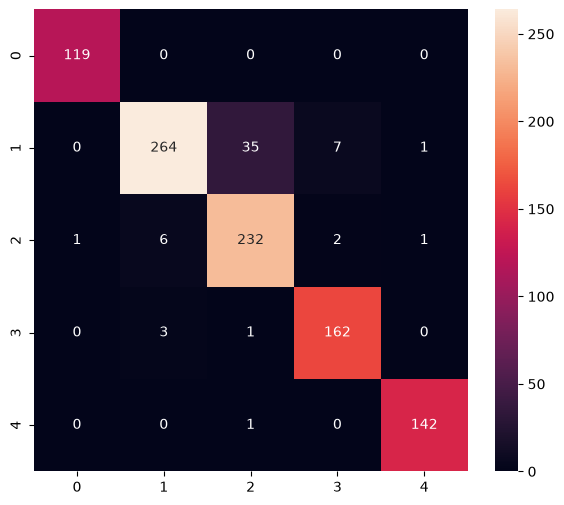

Classification Report
              precision    recall  f1-score   support

           0       0.99      1.00      1.00       119
           1       0.97      0.86      0.91       307
           2       0.86      0.96      0.91       242
           3       0.95      0.98      0.96       166
           4       0.99      0.99      0.99       143

    accuracy                           0.94       977
   macro avg       0.95      0.96      0.95       977
weighted avg       0.94      0.94      0.94       977



In [458]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, classification_report

def print_confusion_matrix(y_true, y_pred, report=True):
    labels = sorted(list(set(y_true)))
    cmx_data = confusion_matrix(y_true, y_pred, labels=labels)
    
    df_cmx = pd.DataFrame(cmx_data, index=labels, columns=labels)
 
    fig, ax = plt.subplots(figsize=(7, 6))
    sns.heatmap(df_cmx, annot=True, fmt='g' ,square=False)
    ax.set_ylim(len(set(y_true)), 0)
    plt.show()
    
    if report:
        print('Classification Report')
        print(classification_report(y_test, y_pred))

Y_pred = model.predict(X_test)
y_pred = np.argmax(Y_pred, axis=1)

print_confusion_matrix(y_test, y_pred)

# Convert to model for Tensorflow-Lite

In [459]:
# Save as a model dedicated to inference
model.save(model_save_path, include_optimizer=False)

In [460]:
# Transform model (quantization)

converter = tf.lite.TFLiteConverter.from_keras_model(model)
converter.optimizations = [tf.lite.Optimize.DEFAULT]
tflite_quantized_model = converter.convert()

open(tflite_save_path, 'wb').write(tflite_quantized_model)

INFO:tensorflow:Assets written to: /var/folders/1k/f7l_vzvx2r964wv7zwh_3rw40000gn/T/tmpp1u_zli1/assets


INFO:tensorflow:Assets written to: /var/folders/1k/f7l_vzvx2r964wv7zwh_3rw40000gn/T/tmpp1u_zli1/assets


Saved artifact at '/var/folders/1k/f7l_vzvx2r964wv7zwh_3rw40000gn/T/tmpp1u_zli1'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 42), dtype=tf.float32, name='input_layer_21')
Output Type:
  TensorSpec(shape=(None, 5), dtype=tf.float32, name=None)
Captures:
  5920180944: TensorSpec(shape=(), dtype=tf.resource, name=None)
  5920180368: TensorSpec(shape=(), dtype=tf.resource, name=None)
  5920182096: TensorSpec(shape=(), dtype=tf.resource, name=None)
  5920182480: TensorSpec(shape=(), dtype=tf.resource, name=None)
  5920186128: TensorSpec(shape=(), dtype=tf.resource, name=None)
  5920178832: TensorSpec(shape=(), dtype=tf.resource, name=None)


W0000 00:00:1792878644.379613 2135586 tf_tfl_flatbuffer_helpers.cc:392] Ignored output_format.
W0000 00:00:1792878644.379621 2135586 tf_tfl_flatbuffer_helpers.cc:395] Ignored drop_control_dependency.


6648

# Inference test

In [461]:
interpreter = tf.lite.Interpreter(model_path=tflite_save_path)
interpreter.allocate_tensors()

In [462]:
# Get I / O tensor
input_details = interpreter.get_input_details()
output_details = interpreter.get_output_details()

In [463]:
interpreter.set_tensor(input_details[0]['index'], np.array([X_test[0]]))

In [464]:
%%time
# Inference implementation
interpreter.invoke()
tflite_results = interpreter.get_tensor(output_details[0]['index'])

CPU times: user 724 μs, sys: 12 μs, total: 736 μs
Wall time: 52.9 μs


In [465]:
print(np.squeeze(tflite_results))
print(np.argmax(np.squeeze(tflite_results)))

[3.3749086e-03 1.7274660e-01 8.2339990e-01 4.0475972e-04 7.3849435e-05]
2
